This notebook reproduces the Methods paragraphs on the **sensitivity of the PPI to the weighting
rule**, **baseline metrics and discriminative validity** (counter vs regular play) and **sex
differences**, and the corresponding Results: Supplementary Tables S1–S2, Figure 2 and the
item decompositions of the counter–regular and men–women PPI differences.

**Input**: `../data/ppi-features.h5` 

In [1]:
import os
import warnings
from math import erfc, sqrt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.cluster import KMeans
from sklearn.metrics import cohen_kappa_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman"]})

DATA_DIR = "../data"
FIG_DIR = "../figures"
PPI_H5 = os.path.join(DATA_DIR, "ppi-features.h5")
os.makedirs(FIG_DIR, exist_ok=True)

KEYS = ["game_id", "possession", "possession_team_id"]
TOURN_ORDER = ["EURO2020", "WC2022", "WEURO2022", "WWC2023", "EURO2024", "WEURO2025"]

ppi = pd.read_hdf(PPI_H5, "ppi")
features = pd.read_hdf(PPI_H5, "features")
w_horst = pd.read_hdf(PPI_H5, "horst_weights")
ITEMS = list(w_horst.index)

# z-scored PPI items (oriented: higher = faster); PPI = standardised Z @ w (Eq. 2)
Z = ppi[[f"z_{k}" for k in ITEMS]].set_axis(ITEMS, axis=1)
_raw = Z.values @ w_horst.values
SD_RAW = _raw.std(ddof=0)
assert np.allclose((_raw - _raw.mean()) / SD_RAW, ppi["PPI"])
print(f"{len(ppi):,} possessions, {ppi['game_id'].nunique()} matches; SD of the raw composite = {SD_RAW:.3f}")

39,995 possessions, 292 matches; SD of the raw composite = 0.491


### Item decomposition of a PPI difference

Because the PPI is a linear composite (Eq. 2), the difference in mean PPI between two groups of
possessions splits exactly into item contributions
$c_k = w_k\,(\bar z_{k,A} - \bar z_{k,B}) / \mathrm{SD}_{\mathrm{raw}}$, which sum to
$\overline{\mathrm{PPI}}_A - \overline{\mathrm{PPI}}_B$.

In [2]:
LABELS = {
    "passes_per_minute": "Passes per minute",
    "distance_per_second": "Ball displacement per second",
    "distance_per_touch": "Ball displacement per touch",
    "time_to_pass": "Inter-pass interval",
    "spatial_compression_x": "Longitudinal spatial spread",
    "spatial_compression_y": "Lateral spatial spread",
    "goal_directed_displacement_per_second": "Goal-directed ball displacement per second",
    "progressive_action_rate": "Progressive action rate",
    "opponents_bypassed_per_second": "Opponents bypassed per second",
}
FACTORS = {                                          # EFA factors (Supplementary Table S4)
    "Directional progression": ["goal_directed_displacement_per_second",
                                "progressive_action_rate", "opponents_bypassed_per_second"],
    "Passing tempo": ["passes_per_minute", "time_to_pass"],
    "Ball speed": ["distance_per_second", "distance_per_touch"],
    "Team spread": ["spatial_compression_x", "spatial_compression_y"],
}


def decompose(mask_a, mask_b, title):
    """Item contributions to mean PPI(A) − mean PPI(B)."""
    c = w_horst * (Z[mask_a].mean() - Z[mask_b].mean()) / SD_RAW
    gap = ppi.loc[mask_a, "PPI"].mean() - ppi.loc[mask_b, "PPI"].mean()
    assert np.isclose(c.sum(), gap)
    out = pd.DataFrame({"contribution": c, "share_%": 100 * c / gap}).rename(index=LABELS)
    by_factor = pd.DataFrame({f: [c[v].sum(), 100 * c[v].sum() / gap]
                              for f, v in FACTORS.items()},
                             index=["contribution", "share_%"]).T
    print(f"=== {title}: ΔPPI = {gap:+.3f} ===")
    print(out.sort_values("contribution", ascending=False).round(3).to_string())
    print(by_factor.round(3).to_string(), "\n")
    return out

## 1 · Sensitivity to the weighting rule (Supplementary Table S1)

The PPI is recomputed with Horst weights from absolute correlations, with equal weights, and with
signed weights re-estimated after omitting each tournament in turn (applied to all possessions).
Each variant is z-standardised and compared with the main PPI by its correlation with the main
index and its K-means (K = 2) partition: boundary (midpoint of the two centres), share of
high-pace possessions and agreement with the main partition (Cohen's κ).

In [3]:
Z_within = Z - Z.groupby(ppi["tournament"]).transform("mean")   # pooled within-tournament


def horst_weights(X, absolute=False):
    R = X.corr()
    w = (R.abs() if absolute else R).sum(axis=0)
    return w / w.sum()


def ppi_from(w):
    raw = Z.values @ w.values
    return (raw - raw.mean()) / raw.std(ddof=0)


def kmeans_states(score):
    km = KMeans(n_clusters=2, random_state=42, n_init=20).fit(score.reshape(-1, 1))
    centres = km.cluster_centers_.ravel()
    return (km.labels_ == centres.argmax()).astype(int), centres.mean()


variants = {"Main: signed Horst": horst_weights(Z_within),
            "Absolute-correlation Horst": horst_weights(Z_within, absolute=True),
            "Equal weights": pd.Series(1 / len(ITEMS), index=ITEMS)}
for t in TOURN_ORDER:
    variants[f"Signed, without {t}"] = horst_weights(Z_within[ppi["tournament"] != t])
assert np.allclose(variants["Main: signed Horst"], w_horst)

w_main = variants["Main: signed Horst"]
ppi_main = ppi_from(w_main)
states_main, _ = kmeans_states(ppi_main)

rows = []
for name, w in variants.items():
    score = ppi_from(w)
    states, boundary = kmeans_states(score)
    rows.append(dict(variant=name, w_min=w.min(), w_max=w.max(),
                     max_abs_dw=(w - w_main).abs().max(),
                     r_main=np.corrcoef(score, ppi_main)[0, 1], boundary=boundary,
                     pct_high=100 * states.mean(), kappa=cohen_kappa_score(states_main, states)))
table_s1 = pd.DataFrame(rows).set_index("variant")

print("=== Weights by variant ===")
print(pd.DataFrame(variants).T.round(3).to_string())
print("\n=== Table S1 ===")
print(table_s1.round(3).to_string())
table_s1.round(4).to_csv(f"{FIG_DIR}/TableS1_weighting_sensitivity.csv")

=== Weights by variant ===
                            passes_per_minute  distance_per_second  distance_per_touch  time_to_pass  spatial_compression_x  spatial_compression_y  goal_directed_displacement_per_second  progressive_action_rate  opponents_bypassed_per_second
Main: signed Horst                      0.138                0.131               0.057         0.121                  0.084                  0.057                                  0.134                    0.132                          0.146
Absolute-correlation Horst              0.111                0.109               0.098         0.109                  0.094                  0.101                                  0.127                    0.122                          0.129
Equal weights                           0.111                0.111               0.111         0.111                  0.111                  0.111                                  0.111                    0.111                          0.111
Signe

## 2 · Baseline metrics

Four established possession-level metrics (bold in Table 1): passes per minute, ball displacement
per second, ball speed per touch (Hamilton, 2013) and inter-pass interval. Each is winsorised at
[P1, P99] and z-standardised over all possessions for which it is defined, and then matched to the
possessions of the PPI sample.

In [4]:
BASELINES = {"passes_per_minute": "Passes per minute",
             "time_to_pass": "Inter-pass interval",
             "ball_speed_per_touch": "Ball speed per touch",
             "distance_per_second": "Ball displacement per second"}
METRICS = {"PPI": "PPI", **BASELINES}


def winsorise_z(s):
    s = s.dropna()
    s = s.clip(s.quantile(0.01), s.quantile(0.99))
    return (s - s.mean()) / s.std(ddof=0)


base_z = features[KEYS].join(features[list(BASELINES)].apply(winsorise_z))
val = ppi[KEYS + ["tournament", "sex", "play_pattern_name", "PPI"]].merge(
    base_z, on=KEYS, how="left", validate="one_to_one")
print(val[list(METRICS)].count().rename("possessions").to_string())

PPI                     39995
passes_per_minute       39995
time_to_pass            37239
ball_speed_per_touch    39875
distance_per_second     39995


## 3 · Discriminative validity: counter vs regular play (Supplementary Table S2)

Possessions whose first event carries the provider play pattern *From Counter* are compared with
*Regular Play* possessions (set-piece, throw-in, goal-kick, keeper and kick-off possessions are
excluded). Inter-pass interval is sign-inverted so that higher = faster for every metric.
Cohen's d uses the pooled SD; 95% CIs come from 2,000 match-level cluster bootstrap resamples.
The analysis is repeated by sex and, for the PPI, by tournament.

In [5]:
kg = val[val["play_pattern_name"].isin(["Regular Play", "From Counter"])].copy()
kg["counter"] = (kg["play_pattern_name"] == "From Counter").astype(int)
kg["time_to_pass"] = -kg["time_to_pass"]                         # higher = faster


def cohen_d(v, g):
    a, b = v[g == 1], v[g == 0]
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1))
                 / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp


def known_groups(data, col, B=2000, seed=2026):
    sub = data.dropna(subset=[col])
    v, g, m = sub[col].to_numpy(), sub["counter"].to_numpy(), sub["game_id"].to_numpy()
    games = np.unique(m)
    rows_of = {gm: np.flatnonzero(m == gm) for gm in games}
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(B):
        ii = np.concatenate([rows_of[gm] for gm in rng.choice(games, len(games), replace=True)])
        if g[ii].sum() >= 2:
            boot.append(cohen_d(v[ii], g[ii]))
    d_lo, d_hi = np.quantile(boot, [0.025, 0.975])
    return dict(n_counter=int(g.sum()), n_regular=int((g == 0).sum()),
                mean_counter=v[g == 1].mean(), mean_regular=v[g == 0].mean(),
                d=cohen_d(v, g), d_lo=d_lo, d_hi=d_hi)


kg_pooled = pd.DataFrame({col: known_groups(kg, col) for col in METRICS}).T
kg_sex = pd.concat({sex: pd.DataFrame({col: known_groups(kg[kg["sex"] == sex], col)
                                       for col in METRICS}).T for sex in ["Men", "Women"]})
kg_tourn = pd.DataFrame({t: known_groups(kg[kg["tournament"] == t], "PPI")
                         for t in TOURN_ORDER}).T

table_s2 = pd.concat({"All tournaments": kg_pooled.rename(index=METRICS),
                      "Men": kg_sex.loc["Men"].rename(index=METRICS),
                      "Women": kg_sex.loc["Women"].rename(index=METRICS),
                      "PPI by tournament": kg_tourn})
print("=== Table S2 · counter vs regular play ===")
print(table_s2.astype(float).round(3).to_string())
table_s2.astype(float).round(4).to_csv(f"{FIG_DIR}/TableS2_counter_vs_regular.csv")

=== Table S2 · counter vs regular play ===
                                                n_counter  n_regular  mean_counter  mean_regular      d   d_lo   d_hi
All tournaments   PPI                               750.0    16302.0         0.535        -0.142  0.736  0.632  0.844
                  Passes per minute                 750.0    16302.0        -0.516        -0.039 -0.505 -0.595 -0.408
                  Inter-pass interval               503.0    15427.0         0.132         0.118  0.015 -0.114  0.138
                  Ball speed per touch              748.0    16277.0         0.331        -0.241  0.893  0.780  1.003
                  Ball displacement per second      750.0    16302.0        -0.187        -0.297  0.156  0.082  0.229
Men               PPI                               427.0     8712.0         0.708        -0.006  0.781  0.640  0.935
                  Passes per minute                 427.0     8712.0        -0.402         0.015 -0.440 -0.557 -0.310
             

In [6]:
_ = decompose(ppi["play_pattern_name"] == "From Counter",
              ppi["play_pattern_name"] == "Regular Play", "Counter − regular play")

=== Counter − regular play: ΔPPI = +0.677 ===
                                            contribution  share_%
Goal-directed ball displacement per second         0.513   75.823
Progressive action rate                            0.347   51.287
Opponents bypassed per second                      0.206   30.478
Ball displacement per second                       0.034    5.024
Ball displacement per touch                        0.006    0.950
Longitudinal spatial spread                       -0.072  -10.608
Lateral spatial spread                            -0.094  -13.911
Inter-pass interval                               -0.125  -18.472
Passes per minute                                 -0.139  -20.571
                         contribution  share_%
Directional progression         1.066  157.587
Passing tempo                  -0.264  -39.043
Ball speed                      0.040    5.974
Team spread                    -0.166  -24.519 



## 4 · Sex differences

Sex sensitivity of the PPI and the four baselines: linear mixed-effects model per metric
(z-scored metric ~ sex, reference = women, random intercept per match). The PPI difference
between men's and women's possessions is then decomposed into item contributions (Eq. 2).

In [7]:
def fit_mixedlm(formula, data, groups):
    """MixedLM (REML) refitted with several optimisers; keeps the best log-likelihood."""
    model = smf.mixedlm(formula, data=data, groups=groups)
    fits = []
    for method in ("powell", "bfgs", "lbfgs", "nm"):
        try:
            fits.append(model.fit(method=method, reml=True, disp=False))
        except Exception:
            pass
    return max(fits, key=lambda r: r.llf)


def sex_lmm(col):
    sub = val[[col, "sex", "game_id"]].dropna().rename(columns={col: "y"})
    res = fit_mixedlm("y ~ C(sex, Treatment('Women'))", sub, sub["game_id"])
    k = "C(sex, Treatment('Women'))[T.Men]"
    lo, hi = res.conf_int().loc[k]
    return dict(beta=res.params[k], ci_lo=lo, ci_hi=hi, p=res.pvalues[k],
                n=int(res.nobs), n_matches=sub["game_id"].nunique())


sex_res = pd.DataFrame({col: sex_lmm(col) for col in METRICS}).T
print("=== Sex effect (men − women, β on the z-scale) ===")
print(sex_res.rename(index=METRICS).astype(float).round(4).to_string())
print("\nPPI by sex (mean ± SD):")
print(ppi.groupby("sex")["PPI"].agg(["mean", "std"]).round(3).to_string())

=== Sex effect (men − women, β on the z-scale) ===
                                beta   ci_lo   ci_hi       p        n  n_matches
PPI                           0.2573  0.2244  0.2902  0.0000  39995.0      292.0
Passes per minute             0.0571  0.0281  0.0862  0.0001  39995.0      292.0
Inter-pass interval          -0.1375 -0.1708 -0.1043  0.0000  37239.0      292.0
Ball speed per touch         -0.0340 -0.0546 -0.0135  0.0012  39875.0      292.0
Ball displacement per second  0.1617  0.1304  0.1930  0.0000  39995.0      292.0

PPI by sex (mean ± SD):
        mean    std
sex                
Men    0.117  0.961
Women -0.140  1.028


In [8]:
_ = decompose(ppi["sex"] == "Men", ppi["sex"] == "Women", "Men − women")

=== Men − women: ΔPPI = +0.257 ===
                                            contribution  share_%
Longitudinal spatial spread                        0.089   34.412
Lateral spatial spread                             0.065   25.267
Ball displacement per second                       0.049   18.921
Inter-pass interval                                0.040   15.626
Passes per minute                                  0.017    6.547
Ball displacement per touch                        0.016    6.066
Opponents bypassed per second                      0.009    3.523
Goal-directed ball displacement per second        -0.011   -4.233
Progressive action rate                           -0.016   -6.130
                         contribution  share_%
Directional progression        -0.018   -6.839
Passing tempo                   0.057   22.173
Ball speed                      0.064   24.987
Team spread                     0.153   59.679 



## 5 · Figure 2 — sensitivity of the PPI and baseline metrics

(a) Counter vs regular play, Cohen's d with bootstrap 95% CI (significance from the normal
approximation of the bootstrap CI); (b) sex effect, LMM β with 95% CI.
Positive values = higher for counters (a) or men (b).

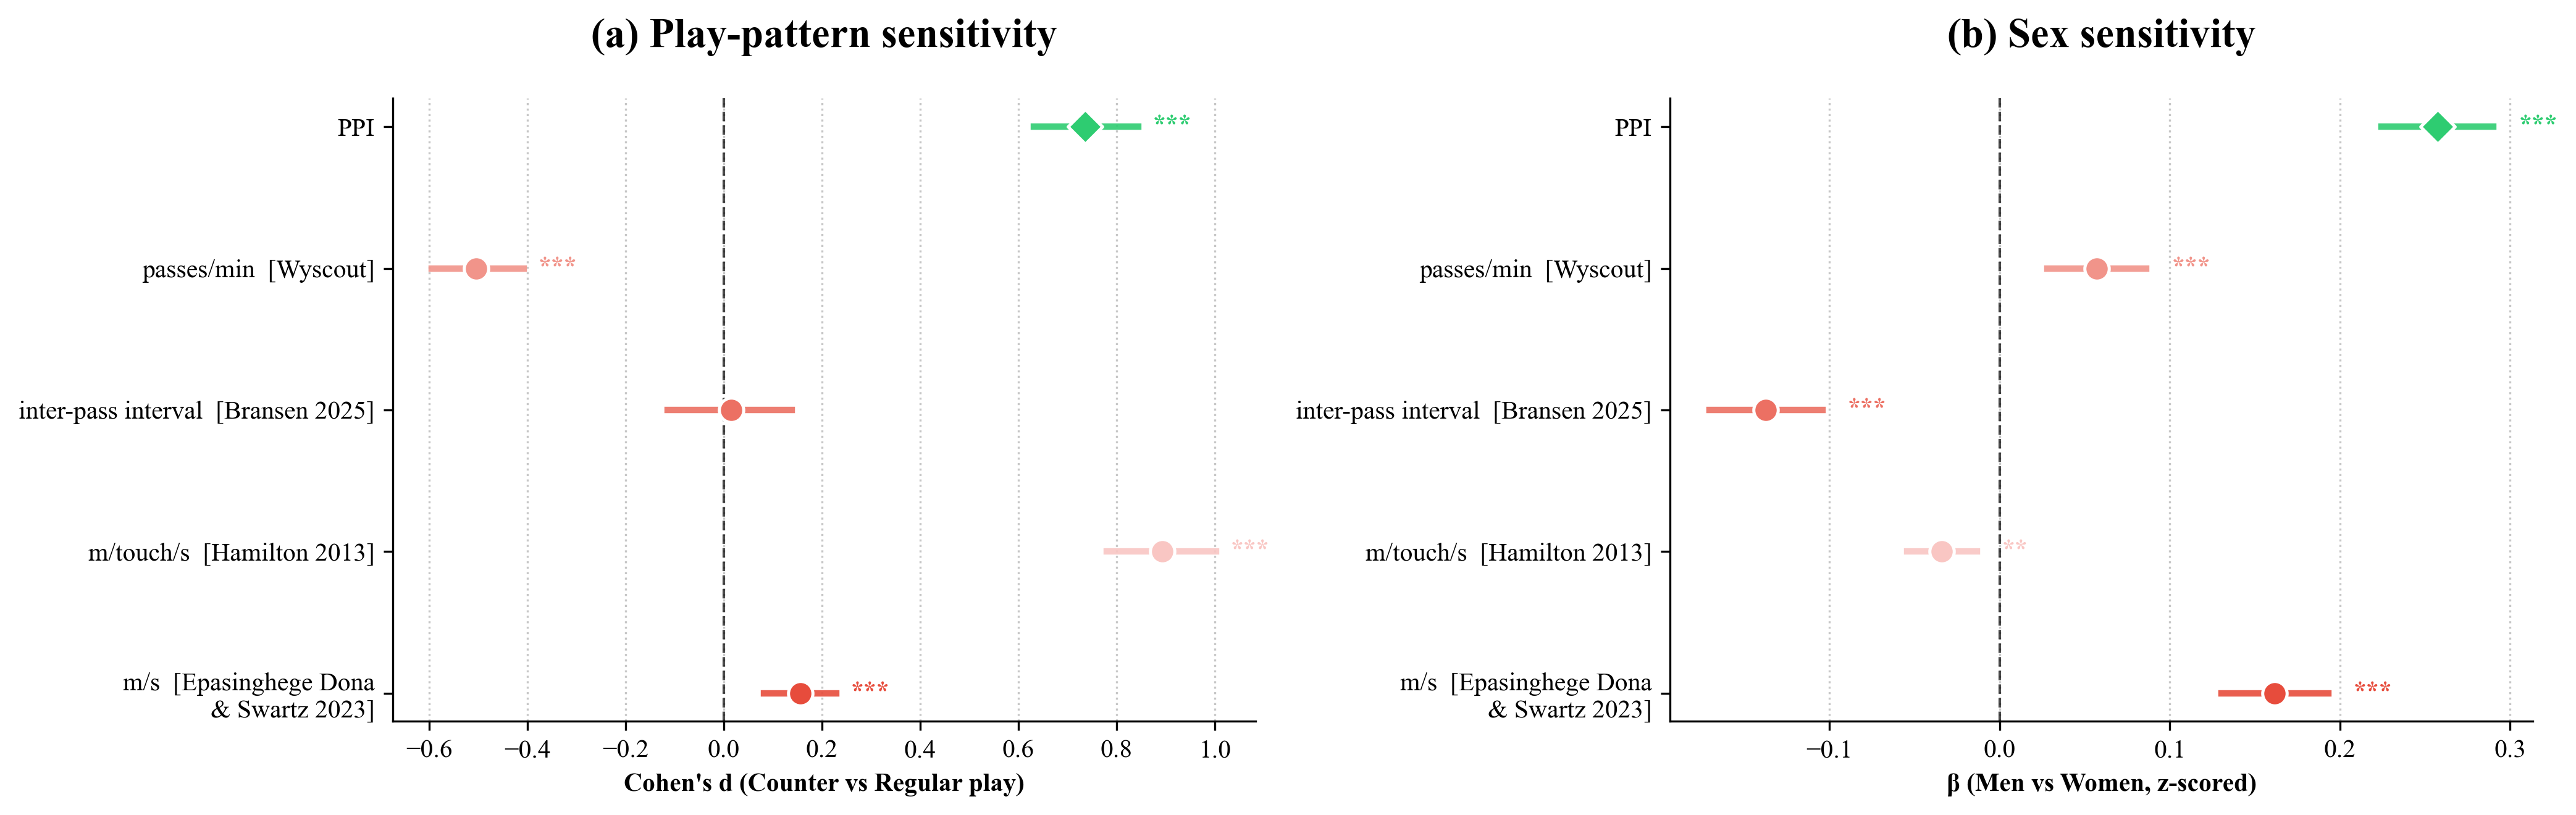

In [9]:
FIG_LABELS = {"PPI": "PPI",
              "passes_per_minute": "passes/min  [Wyscout]",
              "time_to_pass": "inter-pass interval  [Bransen 2025]",
              "ball_speed_per_touch": "m/touch/s  [Hamilton 2013]",
              "distance_per_second": "m/s  [Epasinghege Dona\n& Swartz 2023]"}
FIG_COLORS = {"PPI": "#2ecc71", "passes_per_minute": "#f1948a", "time_to_pass": "#ec7063",
              "ball_speed_per_touch": "#f9c6c3", "distance_per_second": "#e74c3c"}


def stars(p):
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""


def p_from_ci(est, lo, hi):                       # two-sided p, normal approximation
    return erfc(abs(est / ((hi - lo) / (2 * 1.96))) / sqrt(2))


panel_a = pd.DataFrame({"est": kg_pooled["d"], "lo": kg_pooled["d_lo"], "hi": kg_pooled["d_hi"]}).astype(float)
panel_a["sig"] = [stars(p_from_ci(*r)) for r in panel_a[["est", "lo", "hi"]].values]
panel_b = pd.DataFrame({"est": sex_res["beta"], "lo": sex_res["ci_lo"], "hi": sex_res["ci_hi"]}).astype(float)
panel_b["sig"] = sex_res["p"].astype(float).map(stars)


def forest(ax, res, xlabel, title, star_offset):
    for i, m in enumerate(METRICS):
        r, c = res.loc[m], FIG_COLORS[m]
        ax.plot([r["lo"], r["hi"]], [i, i], color=c, lw=2.5, alpha=0.9)
        ax.scatter(r["est"], i, color=c, edgecolor="white", linewidth=1.2, zorder=5, s=90,
                   marker="D" if m == "PPI" else "o")
        if r["sig"]:
            ax.text(r["hi"] + star_offset, i, r["sig"], va="center", fontsize=10, color=c,
                    fontweight="bold")
    ax.axvline(0, color="black", lw=1, ls="--", alpha=0.7)
    ax.set_yticks(np.arange(len(METRICS)), [FIG_LABELS[m] for m in METRICS])
    ax.set_xlabel(xlabel, fontweight="bold")
    ax.set_title(title, fontweight="bold", fontsize=16, pad=20)
    ax.invert_yaxis()
    ax.grid(axis="x", linestyle=":", alpha=0.7)
    sns.despine(ax=ax)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=300)
forest(axes[0], panel_a, "Cohen's d (Counter vs Regular play)", "(a) Play-pattern sensitivity", 0.03)
forest(axes[1], panel_b, "β (Men vs Women, z-scored)", "(b) Sex sensitivity", 0.015)
plt.tight_layout()
for ext in ("png", "pdf"):
    fig.savefig(f"{FIG_DIR}/Figure2_counter_and_sex_sensitivity.{ext}", dpi=300, bbox_inches="tight")
plt.show()